## Loading the Dataset

Load the dataset from a CSV file.  
Name three columns as: 
- **id**: record identifier.
- **color**: associated attribute.
- **symptoms**: described symptoms for each patient.

We use `pandas` to read the file and convert it into a DataFrame.

In [1]:
import pandas as pd


data = pd.read_csv('Student_Dataset.csv', header=None, names=['id', 'color', 'symptoms'], engine='python')

In [2]:
display(data.head(5))

,id,color,symptoms
0,1,On uneven paths the heel feels wobbly side‑to‑...,None
1,2,0x000000,"The feverish feeling eased, but I’m now breath..."
2,3,0x000000,"While working in the garden, I touched a metal..."
3,4,A short sprint brought on a twinge in the midd...,None
4,5,0x000000,I accidentally left my hand on a hot mug for a...



## Handling Missing Values

Some rows may contain missing values in the **symptoms** column.


- Fill missing **symptoms** with **color** when **symptoms** is `None`.
- Set **color** to `None` after filling **symptoms**.

In [3]:
mask = data['symptoms'].isnull() & data['color'].notnull()

data.loc[mask, 'symptoms'] = data.loc[mask, 'color']

data.loc[mask, 'color'] = None

In [4]:
display(data.head(5))

,id,color,symptoms
0,1,None,On uneven paths the heel feels wobbly side‑to‑...
1,2,0x000000,"The feverish feeling eased, but I’m now breath..."
2,3,0x000000,"While working in the garden, I touched a metal..."
3,4,None,A short sprint brought on a twinge in the midd...
4,5,0x000000,I accidentally left my hand on a hot mug for a...


## Text Transformation

`TfidfVectorizer` is used to convert text data into a numerical representation based on the importance of words within the documents.

- `lowercase=True`  
  Converts all text to lowercase.

- `stop_words='english'`  
  Removes common English words (e.g., *the, and, is*).
  This helps to reduce noice in the data

- `max_features=1000`  
  Limits the vocabulary to the top 1000 most important words based on their frequency across the dataset

`fit_transform` reads the text in the `symptoms` column and take the most important words, then converts each text into numbers based in this words 



In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
from sklearn.decomposition import TruncatedSVD

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words='english',
    max_features=1000
)

x = vectorizer.fit_transform(data['symptoms'])
x = normalize(x)
svd = TruncatedSVD(n_components=50, random_state=42)
x_reduced = svd.fit_transform(x)


## Dimensionality Reduction

First, the data is normalized so that all vectors have the same scale.
This helps to improve the clustering algorithm.

Then, TruncatedSVD is applied to reduce the number of dimensions in the data.

Instead of working with a very large number of features, the data is reduced to 50 components, while keeping most of the important information.

- `normalize(x)`  scales the vector
- `TruncatedSVD` reduce dimension
- `n_components=50` keeps the 50 most important components

In [ ]:
from sklearn.preprocessing import normalize
from sklearn.decomposition import TruncatedSVD

x = normalize(x)
svd = TruncatedSVD(n_components=50, random_state=42)
x_reduced = svd.fit_transform(x)


## Create the Clusters

### Find the Optimal Number of Clusters

Instead of choosing the number of clusters manually, we test several values and select the best one using the **Silhouette Score**.

The silhouette score measures how well the data points fit within their clusters.
A **higher score means better cluster separation**.

- A loop tests different values of k from 2 to 19.
- For each value, a **KMeans model** is trained.
- The **silhouette** score is calculated and stored.

The value of **k with the highest score** is selected as the optimal number of clusters.



### Train the Final K-Means Model

After finding the best number of clusters:

- `n_clusters` is set to the optimal value.
- A **KMeans model** is created using this number of clusters.
- The model assigns each data point to a cluster.

The resulting cluster label is stored in a new column:

- `data['cluster']`

Each row in the dataset now belongs to a cluster (0, 1, 2, ...).

In [20]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

scores = {}

for k in range(2, 20):
    km = KMeans(n_clusters=k, random_state=42, n_init='auto')
    labels = km.fit_predict(x_reduced)
    score = silhouette_score(x_reduced, labels)
    scores[k] = score

# Mejor K
n_clusters = max(scores, key=scores.get)
print(f"\nOptimal number: {n_clusters}")

kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init='auto')
data['cluster'] = kmeans.fit_predict(x_reduced)


Número óptimo de clusters: 14


## Visualize the Clusters

To visualize the data, **t-SNE (t-Distributed Stochastic Neighbor Embedding)** is used.

t-SNE reduces high-dimensional data to **2 dimensions**, making it possible observe the clusters in a graph.

- `n_components` = 2
Reduces the data to two dimensions so it can be visualized in a 2D graph.
- `perplexity` = 10
Controls how t-SNE balances local and global structure in the data.
- `init` = 'pca'
Initializes the algorithm using PCA to improve stability.
- `X_2d = tsne.fit_transform(x_reduced)`
Transforms the reduced data into 2D coordinates that can be used for visualization.

Each point in the resulting plot represents a data sample positioned according to its similarity with others.

In [21]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    perplexity=10,
    learning_rate='auto',
    init='pca',
    random_state=42
)

X_2d = tsne.fit_transform(x_reduced)

## Plot the Clusters

The clusters are visualized using a **scatter plot**.

Each point represents a data sample positioned using the **2D coordinates produced by t-SNE**.

- `X_2d[:, 0]` and `X_2d[:, 1]`
These are the two dimensions generated by t-SNE.
- `c=data["cluster"]`
Colors the points according to the cluster assigned by K-Means.
- `cmap="viridis"`
Defines the color palette used to distinguish clusters.

The plot allows us to visually observe how the algorithm grouped similar data points together.

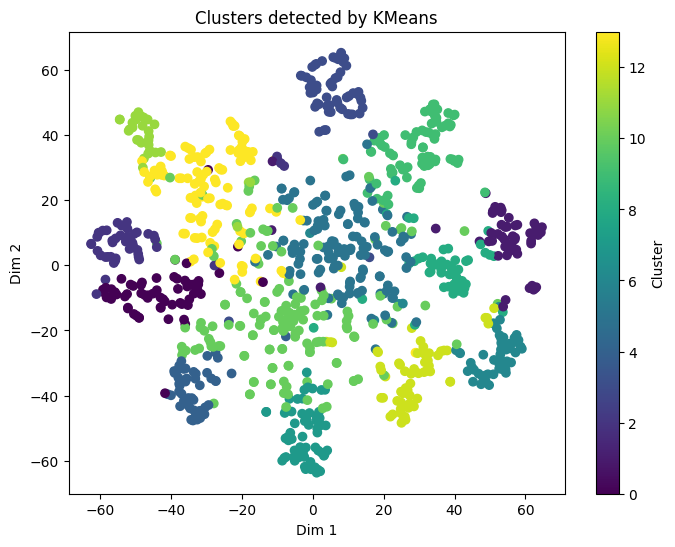

In [22]:
from matplotlib import pyplot as plt
plt.figure(figsize=(8,6))

plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=data["cluster"],
    cmap="viridis"
    # s=50
)

plt.title("Clusters detected by KMeans")
plt.xlabel("Dim 1")
plt.ylabel("Dim 2")
plt.colorbar(label="Cluster")
plt.show()

In [23]:
for i in range(n_clusters):
    print(f"\nCluster {i}:")
    print(data[data["cluster"] == i]["symptoms"].head(10).tolist())


Cluster 0:
['At the base of my thumb toward the wrist there’s a tiny sore spot. Pinching or pressing a jar lid sets it off for a while.', 'Opening bottles and turning keys makes the base of my thumb feel loose and achy. Holding a book for a long time tires the joint quickly.', 'Waking up, my jaw feels tired and sore near the cheek. Chewing tougher foods brings a dull ache that eases if I rest the jaw.', 'Pinching a key between my thumb and index feels weak, like I can’t make a firm circle. Turning a small screw is clumsy though the hand doesn’t feel numb.', 'Turning a stiff key gives a line of soreness along the inner front of my forearm. Pouring from a heavy pan with the palm down brings a quick sting.', 'Catching my thumb on a jacket made the base joint sore. Pinching keys or opening packets hurts along the inner side of that joint.', 'Wearing a snug watchband makes the back of my thumb and hand tingle. Light touch there feels oddly buzzy, and I avoid resting my wrist on the desk ed

In [24]:
import numpy as np

terms = vectorizer.get_feature_names_out()

for i in range(n_clusters):
    center = kmeans.cluster_centers_[i]
    top_words = [terms[i] for i in center.argsort()[-10:]]
    print(f"Cluster {i}: {top_words}")

Cluster 0: ['ache', 'antibiotic', 'appetite', 'asked', 'ankle', 'achy', 'active', 'activity', 'able', '37']
Cluster 1: ['away', 'awkward', 'allergy', 'accompanied', 'attack', 'ago', 'anti', 'able', 'accidentally', '37']
Cluster 2: ['attached', 'appear', 'assumed', 'afterward', 'allergies', 'able', 'air', 'allergic', '37', 'active']
Cluster 3: ['air', 'afternoon', 'aching', 'aches', 'abdomen', 'accompanied', 'achy', 'accidentally', 'able', '37']
Cluster 4: ['allergy', 'bad', 'afternoon', 'area', 'air', 'activities', 'afterward', '37', 'accompanied', 'ache']
Cluster 5: ['attached', 'assumed', 'ankle', 'avoiding', 'allergy', 'attack', 'abdomen', 'afterward', 'aches', '37']
Cluster 6: ['appearing', 'ball', 'ankle', 'ache', 'abdomen', 'allergic', 'aggravate', 'accidentally', '37', 'achy']
Cluster 7: ['avoid', 'avoiding', 'appetite', 'ankles', 'anxiety', 'achy', 'area', 'aching', '37', 'accompanied']
Cluster 8: ['afternoon', 'antibiotic', 'asked', 'abdomen', 'accidentally', 'afterward', 'act